# Equal-Area Maps with CartoGrid

This tutorial shows how to build **equal-area** map figures with `cartogrid`. It uses the same NCEP/DOE Reanalysis II surface temperature data as `tutorial.ipynb` (`dummy_data/air.2m.gauss.2022.nc`).

## Why equal-area projections?

Rectangular projections such as `PlateCarree` (lon/lat) or `Mercator` stretch high latitudes: Greenland looks as large as Africa, even though Africa is about 14 times bigger. For fields that we judge by **area**, such as precipitation coverage, sea-ice extent or the spread of a temperature anomaly, that distortion can mislead the reader.

On an **equal-area** (equivalent) projection, every region keeps its true area relative to the others. Shapes are distorted instead, especially near the edges of the map. Cartopy provides several equal-area projections:

| Projection | Cartopy class | Typical use |
|---|---|---|
| Equal Earth | `ccrs.EqualEarth()` | Global maps (modern, good-looking default) |
| Mollweide | `ccrs.Mollweide()` | Global maps, classic in climate science |
| Lambert Cylindrical | `ccrs.LambertCylindrical()` | Tropical belts (rectangular, but squeezed poleward) |
| Sinusoidal | `ccrs.Sinusoidal()` | Global maps, satellite products (e.g. MODIS) |
| Albers Equal Area | `ccrs.AlbersEqualArea()` | Mid-latitude regions (continents, countries) |
| Lambert Azimuthal Equal Area | `ccrs.LambertAzimuthalEqualArea()` | Polar caps or regions around a point |

## 1. Imports and data

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point

# To ignore warnings
import warnings
warnings.filterwarnings("ignore")

import seaborn as sns
sns.set_theme(style="white")
sns.set_context('notebook', font_scale=1.0)

# Import the module
import cartogrid as cg

Load the temperature data and compute anomalies, as in `tutorial.ipynb`:

In [2]:
# Open the netCDF dataset
ds = xr.open_dataset('dummy_data/air.2m.gauss.2022.nc')

# Convert Kelvin → Celsius
air = ds['air'] - 273.15

# Time-mean climatology (lat, lon) and anomalies (time, lat, lon)
climatology = air.mean(dim='time')
air_anom = air - climatology

# Extract coordinates
time = pd.to_datetime(ds['time'].values)
lat = ds['lat'].values
lon = ds['lon'].values

print(air.dims, air.shape)
print(f'lon: {lon.min():.2f} to {lon.max():.2f},  lat: {lat.min():.2f} to {lat.max():.2f}')

('time', 'level', 'lat', 'lon') (365, 1, 94, 192)
lon: 0.00 to 358.12,  lat: -88.54 to 88.54


The longitudes run from 0° to 358.125°. Without the 360° column, global maps show a thin white seam at the meridian where the data wrap around. `add_cyclic_point` appends that column. We wrap it in a small function so every example can use it:

In [3]:
def cyclic(field, lon):
    # Return (field_cyclic, lon_cyclic) with the first longitude repeated at the end.
    data, lon_c = add_cyclic_point(np.asarray(field), coord=lon)
    return data, lon_c


# Quick test with the first time step at the surface level
data_c, lon_c = cyclic(air[0, 0], lon)
print(data_c.shape, lon_c[-1])

(94, 193) 360.0


## 2. `cg.add_map_features_ea`: map features for any projection

`cg.add_map_features_ea` is the equal-area counterpart of `cg.add_map_features`. It accepts the same main arguments (`lon_step`, `lat_step`, `map_resolution`, `countries`, `coastline`, `rivers`, `fontsize_latlon`, `number_format`, and the `lw_*` / `color_*` keyword arguments), but it draws the graticule and its labels with `ax.gridlines()`, which works on every Cartopy projection.

Its extra arguments are:

| Argument | What it does |
|---|---|
| `left_labels`, `bottom_labels`, `top_labels`, `right_labels` | Turn labels on/off on each edge. This replaces the `ax.set_yticklabels([])` / `ax.set_xticklabels([])` trick from the other tutorial, which has no effect with gridline labels. |
| `central_longitude` | Longitude the meridians are anchored on. By default it is read from the projection, so `EqualEarth(central_longitude=180)` with `lon_step=60` puts meridians at 180°, 120°W, 60°W, 0°, ... Values in -180…180 or 0…360 are both accepted. |
| `lon_convention` | `'180'` (default) writes labels as 120°W / 0° / 60°E; `'360'` writes them as 240°E / 0°E / 60°E, to match data stored on a 0…360 grid. |
| `lon_ticks`, `lat_ticks` | Explicit meridians/parallels, overriding `lon_step` / `lat_step`. `lon_ticks` can be given in either convention, e.g. `[200, 250, 300]` or `[-160, -110, -60]`. |

Run `help(cg.add_map_features_ea)` for the full docstring. The cell below draws the same Equal Earth map, centered on 180°, with the two label conventions:

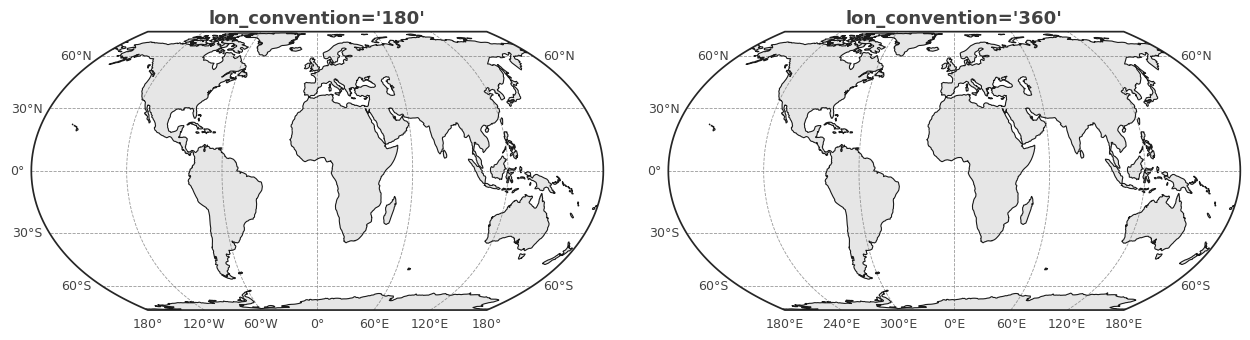

In [ ]:
proj = ccrs.EqualEarth(central_longitude=180)

num_rows, num_columns = 1, 2
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns, horiz_spacing=0.05, left_border=0.04)

font_prop_title = {'fontsize': 13, 'fontweight': 'semibold', 'color': '#434343'}

fig = plt.figure(figsize=(13, 3.4))

for ci, convention in enumerate(['180', '360']):
    ax = fig.add_axes([x_coords[ci], y_coords[0], x_fig, y_fig],
                      projection=proj)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor='#e6e6e6', zorder=0)
    ax = cg.add_map_features_ea(ax, lon_step=60, lat_step=30,
                                lon_convention=convention)
    ax.set_title(f"lon_convention='{convention}'", fontdict=font_prop_title)

## 3. Why it matters: PlateCarree vs. Equal Earth

Before plotting data, here is the distortion itself. `ax.tissot()` draws **Tissot's indicatrices**: circles that all have the same true radius (here 500 km) on the Earth's surface.

* On **PlateCarree** (left) the circles grow wider toward the poles, so high latitudes look larger than they are.
* On **Equal Earth** (right) every circle covers the same map area. Their shapes get squashed near the edges, but their areas stay correct.

Both panels are laid out with `cg.define_grid_fig`, as in `tutorial.ipynb`.

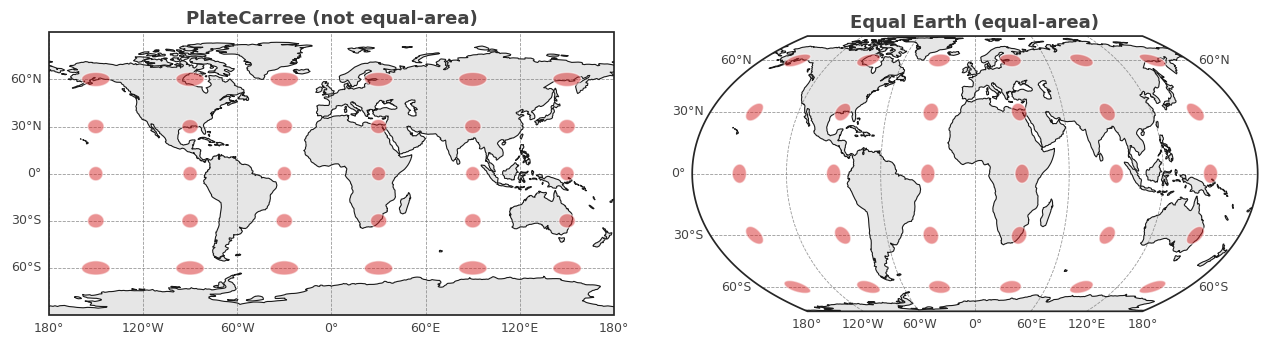

In [5]:
# Two panels side by side: rectangular vs. equal-area
projections = [ccrs.PlateCarree(central_longitude=0),
               ccrs.EqualEarth(central_longitude=0)]
titles = ['PlateCarree (not equal-area)', 'Equal Earth (equal-area)']

num_rows, num_columns = 1, 2
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns, horiz_spacing=0.06, left_border=0.04)

font_prop_title = {'fontsize': 13, 'fontweight': 'semibold', 'color': '#434343'}

fig = plt.figure(figsize=(13, 3.6))

for ci, (proj, title) in enumerate(zip(projections, titles)):
    ax = fig.add_axes([x_coords[ci], y_coords[0], x_fig, y_fig],
                      projection=proj)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor='#e6e6e6', zorder=0)
    ax = cg.add_map_features_ea(ax, lon_step=60, lat_step=30)

    # Circles of identical true radius (500 km) on a regular lon/lat lattice
    ax.tissot(rad_km=500, lons=np.arange(-150, 181, 60),
              lats=np.arange(-60, 61, 30), n_samples=60,
              facecolor='tab:red', alpha=0.5, zorder=12)

    ax.set_title(title, fontdict=font_prop_title)

fig.savefig('figures/equalarea_example_0.png', dpi=150,
            bbox_inches='tight', facecolor='white')

## 4. A single global equal-area map

This follows the same pattern as `example_1` in `tutorial.ipynb`, with three changes:

* `proj = ccrs.EqualEarth(central_longitude=180)` replaces `PlateCarree`. Centering on 180° keeps the Pacific in one piece.
* `ax.set_global()` replaces `set_extent`, and there is **no** `set_aspect('auto')`.
* `figsize=(8, 4.2)` roughly matches the ≈ 2:1 shape of Equal Earth, so the map fills its axes without large white margins.

The horizontal colorbar comes from `cg.add_colorbar`, exactly as before.

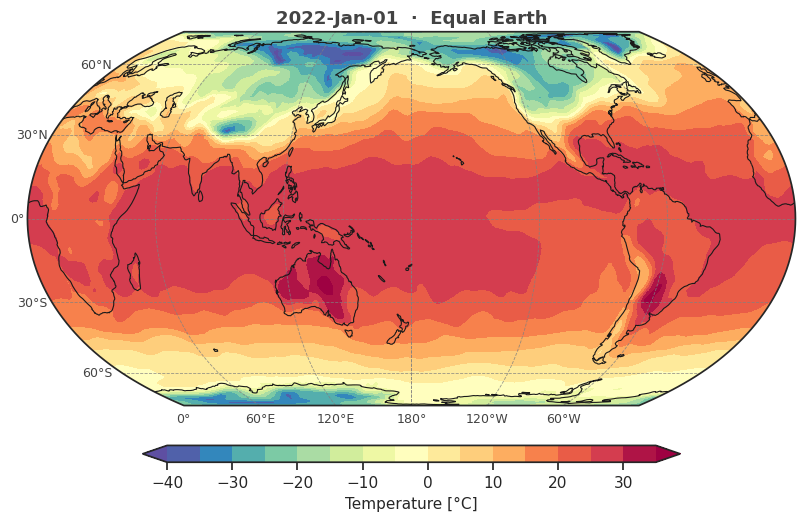

In [6]:
proj = ccrs.EqualEarth(central_longitude=180)

num_rows, num_columns = 1, 1
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns)

fig = plt.figure(figsize=(8, 4.2))

idx = 0
levels = np.linspace(-40, 35, 16)
cmap = sns.color_palette("Spectral_r", as_cmap=True)

ax = fig.add_axes([x_coords[0], y_coords[0], x_fig, y_fig], projection=proj)
ax.set_global()
ax = cg.add_map_features_ea(ax, lon_step=60, lat_step=30, map_resolution=110)

# Add the cyclic point and plot
data_c, lon_c = cyclic(air[idx, 0], lon)
cs = ax.contourf(lon_c, lat, data_c, levels, cmap=cmap, extend='both',
                 transform=ccrs.PlateCarree())

ax.set_title(f"{time[idx].strftime('%Y-%b-%d')}  ·  Equal Earth",
             fontdict=font_prop_title)

cg.add_colorbar(fig, cs, 'Temperature [°C]', 'horizontal', grid_prop,
                cbar_factor=0.7, cbar_width=0.04, y_coord_cbar=-0.08,
                fontsize=11)

fig.savefig('figures/equalarea_example_1.png', dpi=150,
            bbox_inches='tight', facecolor='white')

## 5. Comparing equal-area projections in one grid

Each panel can have its own projection: just pass a different `projection=` to `fig.add_axes`. Here a 2 × 2 grid shows four global equal-area projections of the same field, sharing one vertical colorbar.

Note how `left_labels` and `bottom_labels` replace the `set_yticklabels([])` / `set_xticklabels([])` logic. Because every panel here uses a different projection, we keep the labels on all of them. In a grid where all panels share one projection, you would typically pass `left_labels=(ci == 0)` and `bottom_labels=(ri == num_rows - 1)` (see section 6).

Notice also that on projections whose meridians meet at a pointed pole (**Mollweide**, **Sinusoidal**), the longitude labels bunch together along the bottom edge. For labelled multi-panel figures, **Equal Earth** (flat poles) usually gives the cleanest result.

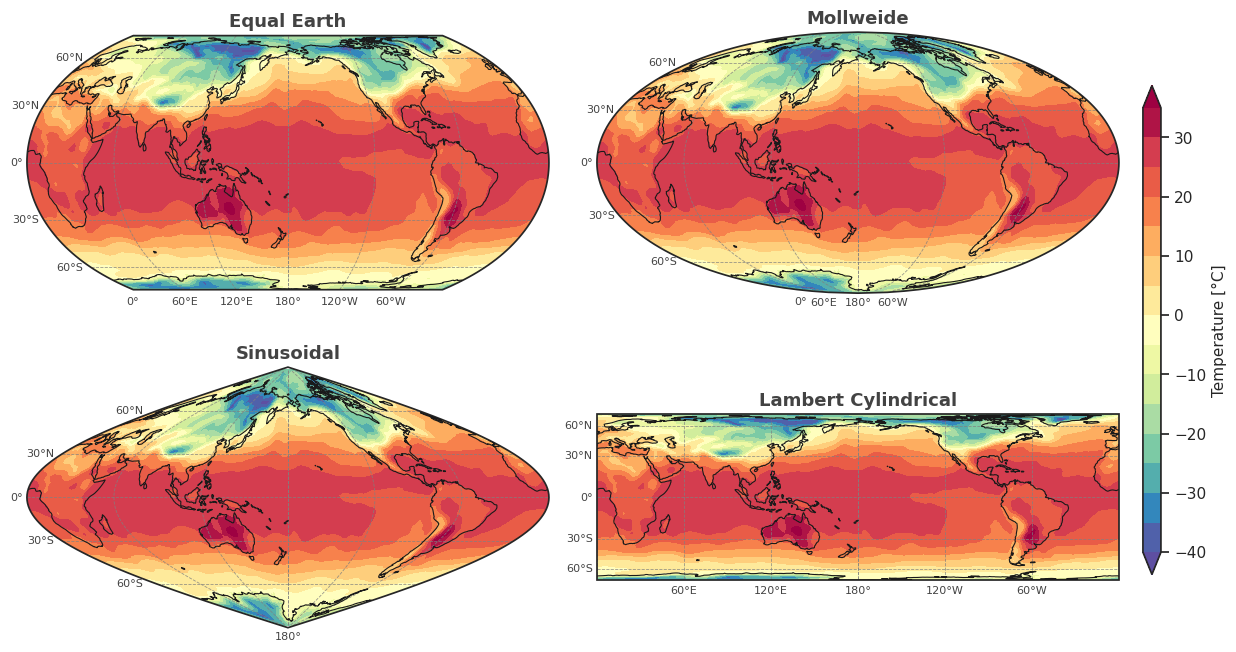

In [7]:
proj_grid = [[ccrs.EqualEarth(central_longitude=180),
              ccrs.Mollweide(central_longitude=180)],
             [ccrs.Sinusoidal(central_longitude=180),
              ccrs.LambertCylindrical(central_longitude=180)]]
names = [['Equal Earth', 'Mollweide'],
         ['Sinusoidal', 'Lambert Cylindrical']]

num_rows, num_columns = 2, 2
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns, horiz_spacing=0.04, vert_spacing=0.09,
    left_border=0.03, right_border=0.06)

fig = plt.figure(figsize=(12, 6.5))

idx = 0
data_c, lon_c = cyclic(air[idx, 0], lon)

for ri in range(num_rows):
    for ci in range(num_columns):
        ax = fig.add_axes([x_coords[ci], y_coords[ri], x_fig, y_fig],
                          projection=proj_grid[ri][ci])
        ax.set_global()
        ax = cg.add_map_features_ea(ax, lon_step=60, lat_step=30,
                                    fontsize_latlon=8)

        cs = ax.contourf(lon_c, lat, data_c, levels, cmap=cmap,
                         extend='both', transform=ccrs.PlateCarree())
        ax.set_title(names[ri][ci], fontdict=font_prop_title)

cg.add_colorbar(fig, cs, 'Temperature [°C]', 'vertical', grid_prop,
                cbar_factor=0.8, cbar_width=0.015, x_coord_cbar=0.96,
                fontsize=11)

fig.savefig('figures/equalarea_example_2.png', dpi=150,
            bbox_inches='tight', facecolor='white')

## 6. Fields and anomalies with one colorbar per row

This is the equal-area version of `example_3`: the top row shows temperature, the bottom row shows anomalies, and each row has its own colormap and its own colorbar from `cg.add_colorbar_row`.

All panels share the Equal Earth projection, so we label only the outer edges:

```python
ax = cg.add_map_features_ea(ax, left_labels=(ci == 0),
                            bottom_labels=(ri == num_rows - 1))
```

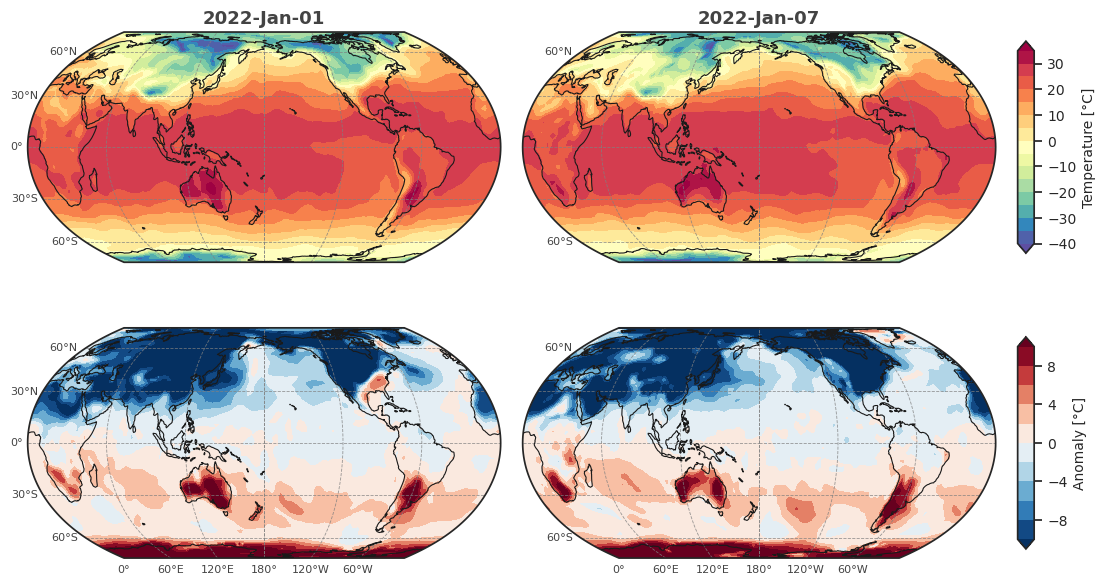

In [8]:
proj = ccrs.EqualEarth(central_longitude=180)

num_rows, num_columns = 2, 2
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns, horiz_spacing=0.02, vert_spacing=0.08,
    left_border=0.04, right_border=0.08)

fig = plt.figure(figsize=(11, 5.8))

levels = np.linspace(-40, 35, 16)
levels_anom = np.linspace(-10, 10, 11)
cmap = sns.color_palette("Spectral_r", as_cmap=True)
cmap_anom = sns.color_palette("RdBu_r", as_cmap=True)

time_idx = [0, 6]          # two dates, one per column

for ri in range(num_rows):
    for ci in range(num_columns):
        ax = fig.add_axes([x_coords[ci], y_coords[ri], x_fig, y_fig],
                          projection=proj)
        ax.set_global()
        ax = cg.add_map_features_ea(ax, lon_step=60, lat_step=30,
                                    fontsize_latlon=8,
                                    left_labels=(ci == 0),
                                    bottom_labels=(ri == num_rows - 1))

        t = time_idx[ci]
        if ri == 0:
            data_c, lon_c = cyclic(air[t, 0], lon)
            cs = ax.contourf(lon_c, lat, data_c, levels, cmap=cmap,
                             extend='both', transform=ccrs.PlateCarree())
            ax.set_title(f"{time[t].strftime('%Y-%b-%d')}",
                         fontdict=font_prop_title)
        else:
            data_c, lon_c = cyclic(air_anom[t, 0], lon)
            cs_anom = ax.contourf(lon_c, lat, data_c, levels_anom,
                                  cmap=cmap_anom, extend='both',
                                  transform=ccrs.PlateCarree())

cg.add_colorbar_row(fig, cs, 'Temperature [°C]', grid_prop=grid_prop,
                    row_idx=0, cbar_factor=0.85, cbar_width=0.015,
                    x_coord_cbar=0.94, fontsize=10)
cg.add_colorbar_row(fig, cs_anom, 'Anomaly [°C]', grid_prop=grid_prop,
                    row_idx=1, cbar_factor=0.85, cbar_width=0.015,
                    x_coord_cbar=0.94, fontsize=10)

fig.savefig('figures/equalarea_example_3.png', dpi=150,
            bbox_inches='tight', facecolor='white')

## 7. Regional equal-area maps

For a region rather than the whole globe, use a projection **centered on that region**:

* **Albers Equal Area** for mid-latitude areas that are wider than they are tall (North America, South America, Europe). Its two `standard_parallels` should sit near 1/6 and 5/6 of the region's latitude range, and they cannot be symmetric about the equator (e.g. `(-35, 35)` is rejected by PROJ).
* **Lambert Azimuthal Equal Area** for regions roughly as tall as they are wide, centered on a point (Africa, polar caps, ...).

Limit the region with `ax.set_extent(..., crs=ccrs.PlateCarree())`. The extent is given in lon/lat, so the CRS must be `PlateCarree` and not the map projection. In `tutorial.ipynb` this was the same object because the map itself was `PlateCarree`.

Below, column 0 shows North America in Albers (15°N–60°N, so `standard_parallels=(22.5, 52.5)`) and column 1 shows Africa in Lambert Azimuthal, centered on (20°E, 0°). Each column gets its own colorbar from `cg.add_colorbar_col`.

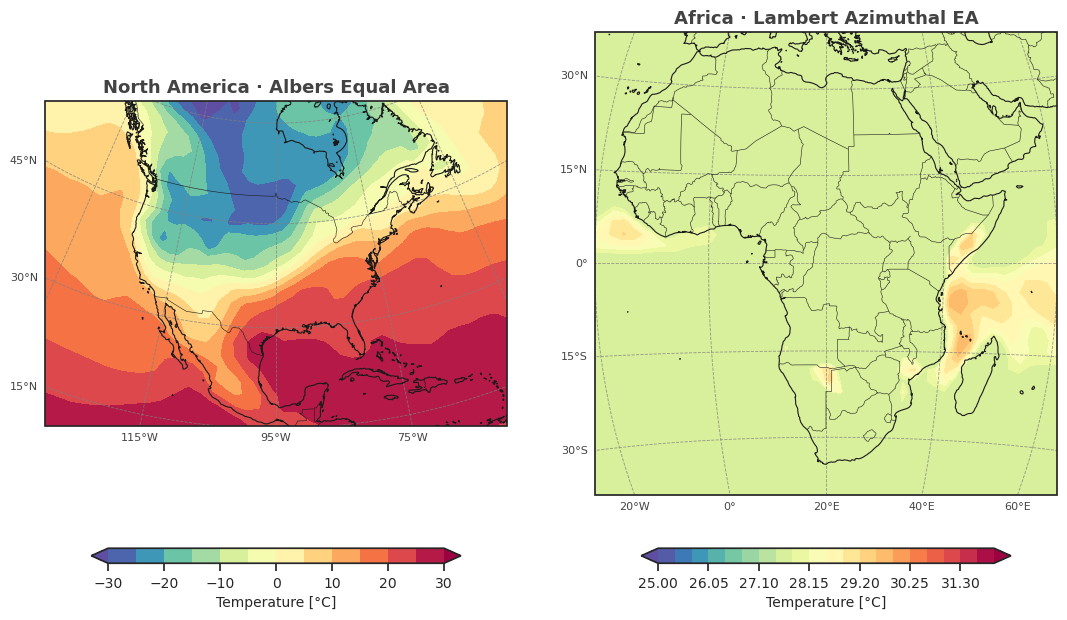

In [21]:
proj_cols = [ccrs.AlbersEqualArea(central_longitude=-95, central_latitude=37.5,
                                  standard_parallels=(22.5, 52.5)),
             ccrs.LambertAzimuthalEqualArea(central_longitude=20,
                                            central_latitude=0)]
extents = [(-130, -60, 15, 60),       # North America (lon/lat)
           (-20, 60, -38, 38)]        # Africa (lon/lat)
titles = ['North America · Albers Equal Area', 'Africa · Lambert Azimuthal EA']

num_rows, num_columns = 1, 2
grid_prop = x_coords, y_coords, x_fig, y_fig = cg.define_grid_fig(
    num_rows, num_columns, horiz_spacing=0.08, left_border=0.05)

fig = plt.figure(figsize=(11, 5))

idx = 0
level_sets = [np.linspace(-30, 30, 13), np.linspace(25, 32, 21)]
cmaps = [sns.color_palette("Spectral_r", as_cmap=True),
         sns.color_palette("Spectral_r", as_cmap=True)]
lon_steps, lat_steps = [20, 20], [15, 15]

data_c, lon_c = cyclic(air[idx, 0], lon)

for ci in range(num_columns):
    ax = fig.add_axes([x_coords[ci], y_coords[0], x_fig, y_fig],
                      projection=proj_cols[ci])
    ax.set_extent(extents[ci], crs=ccrs.PlateCarree())
    ax = cg.add_map_features_ea(ax, lon_step=lon_steps[ci],
                                lat_step=lat_steps[ci], map_resolution=50,
                                countries=True, lw_country=0.4,
                                fontsize_latlon=8)

    cs = ax.contourf(lon_c, lat, data_c, level_sets[ci], cmap=cmaps[ci],
                     extend='both', transform=ccrs.PlateCarree())
    ax.set_title(titles[ci], fontdict=font_prop_title)

    cg.add_colorbar_col(fig, cs, 'Temperature [°C]', grid_prop=grid_prop,
                        col_idx=ci, cbar_factor=0.8, cbar_width=0.03,
                        y_coord_cbar=-0.1, fontsize=10)

fig.savefig('figures/equalarea_example_4.png', dpi=150,
            bbox_inches='tight', facecolor='white')

**Tips**

* A map's projection only changes how the data *look*. When you compute area averages (for example a global-mean temperature), you still have to weight by `np.cos(np.deg2rad(lat))`.
* If a panel shows large white margins, its axes box has a different shape from the projection. Adjust `figsize`, `horiz_spacing` and `vert_spacing` until they match.
* If your data are on a 0…360 grid, pass `lon_convention='360'` to `cg.add_map_features_ea` so the map labels match the coordinates you use in code. Extents and ticks can be given in either convention.